# Welch Procedure — Per-product DQN (order-up-to) vs (s,S)

> **Version 1 (2026-10-27).** Reference = the original baseline (s,S) (20,38)/(19,37). Here the DQN (reward × 1/100) looks better than (s,S) (−2.09 ± 0.32 $/day), but that baseline turned out to be badly tuned: see `welch_procedure_product_dqn_v2.ipynb` (re-tuned (s,S), phase C, ablation) and `docs/experiments/README.md`.

Steady-state analysis of the per-product DQN agents trained on `ProductInventoryEnvironment`
(one controller per product, order-up-to actions, compact observation; see `src/environment/structured_env.py`).

Configurations compared on the **same seeds** (common random numbers via `StreamedInventorySimulation`:
same customers and same k-th lead time per product for every policy):

| Configuration | Product 0 | Product 1 |
|---|---|---|
| `(s,S)` | (s,S) = (20, 38) | (s,S) = (19, 37) |
| `DQN-P0 + (s,S)-P1` | DQN | (s,S) |
| `(s,S)-P0 + DQN-P1` | (s,S) | DQN |
| `DQN + DQN` | DQN | DQN |

Models are produced by `scripts/train_product_dqn.py` (see the README of the run in `models/`).

## Setup & Imports

In [1]:
import sys

sys.path.insert(0, "..")

import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display

from src.agents.metrics import EvaluationMetrics
from src.agents.metrics.joint_evaluation import (
    compare_joint_policies,
    format_comparison,
    run_joint_episode,
    summarize_comparison,
)
from src.environment import ModelProductPolicy, SSProductPolicy
from src.seeds import generate_seeds

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

## Configuration

In [2]:
ROOT = Path("..")

SIM_DAYS = 1000  # Days per replication (about 3 years)
NUM_REPLICATIONS = 300  # Independent runs (~1.6 s per seed for all 4 configurations)
WINDOW_SIZE = 25  # Half-width of the Welch moving average

# Test seeds: same pool as the other notebooks; validation seeds (900+) are disjoint
WELCH_SEEDS = generate_seeds(NUM_REPLICATIONS, start_index=0)
VALIDATION_SEEDS = generate_seeds(5, start_index=900)

# Checkpoints selected on the validation seeds during training
MODEL_DIRS = {
    0: ROOT / "models/dqn_p0_rs100_1M/best",
    1: ROOT / "models/dqn_p1_rs100_1M/best",
}

# Training runs (for the learning curves): label -> run directory per product
TRAINING_RUNS = {
    "reward scale 1/20, lr 1e-4": "ab_1M",
    "reward scale 1/20, lr 3e-5": "lr3e-5_1M",
    "reward scale 1/100, lr 1e-4": "rs100_1M",
}

# Categorical colors, fixed order (one per configuration, never cycled)
COLORS = {
    "(s,S)": "#2a78d6",
    "DQN-P0 + (s,S)-P1": "#eb6834",
    "(s,S)-P0 + DQN-P1": "#1baf7a",
    "DQN + DQN": "#eda100",
}

print(f"📋 Simulation: {SIM_DAYS} days × {NUM_REPLICATIONS} replications")
print(f"   Smoothing window: {WINDOW_SIZE} days")

📋 Simulation: 1000 days × 300 replications
   Smoothing window: 25 days


## Policies

In [3]:
ss = (SSProductPolicy.baseline(0), SSProductPolicy.baseline(1))
dqn = {pid: ModelProductPolicy.load(path, label=f"DQN-P{pid}") for pid, path in MODEL_DIRS.items()}

CONFIGS = {
    "(s,S)": ss,
    "DQN-P0 + (s,S)-P1": (dqn[0], ss[1]),
    "(s,S)-P0 + DQN-P1": (ss[0], dqn[1]),
    "DQN + DQN": (dqn[0], dqn[1]),
}

for pid, path in MODEL_DIRS.items():
    meta = json.loads((path / "dqn_model_metadata.json").read_text())
    print(
        f"P{pid}: {path.relative_to(ROOT)} | checkpoint @ {meta['timesteps']:,} steps | "
        f"reward_scale={meta['reward_scale']} | actions={len(meta['spec']['levels']) + 1} | "
        f"history={meta['spec']['history_length']} days"
    )

P0: models/dqn_p0_rs100_1M/best | checkpoint @ 400,000 steps | reward_scale=0.01 | actions=52 | history=30 days
P1: models/dqn_p1_rs100_1M/best | checkpoint @ 450,000 steps | reward_scale=0.01 | actions=52 | history=21 days


## 1. Simulation (common random numbers)

In [4]:
_, episodes = compare_joint_policies(CONFIGS, WELCH_SEEDS, episode_length=SIM_DAYS)

Evaluating (s,S) on 300 seeds...


Evaluating DQN-P0 + (s,S)-P1 on 300 seeds...


Evaluating (s,S)-P0 + DQN-P1 on 300 seeds...


Evaluating DQN + DQN on 300 seeds...


## 2. Average Daily Cost Across Replications

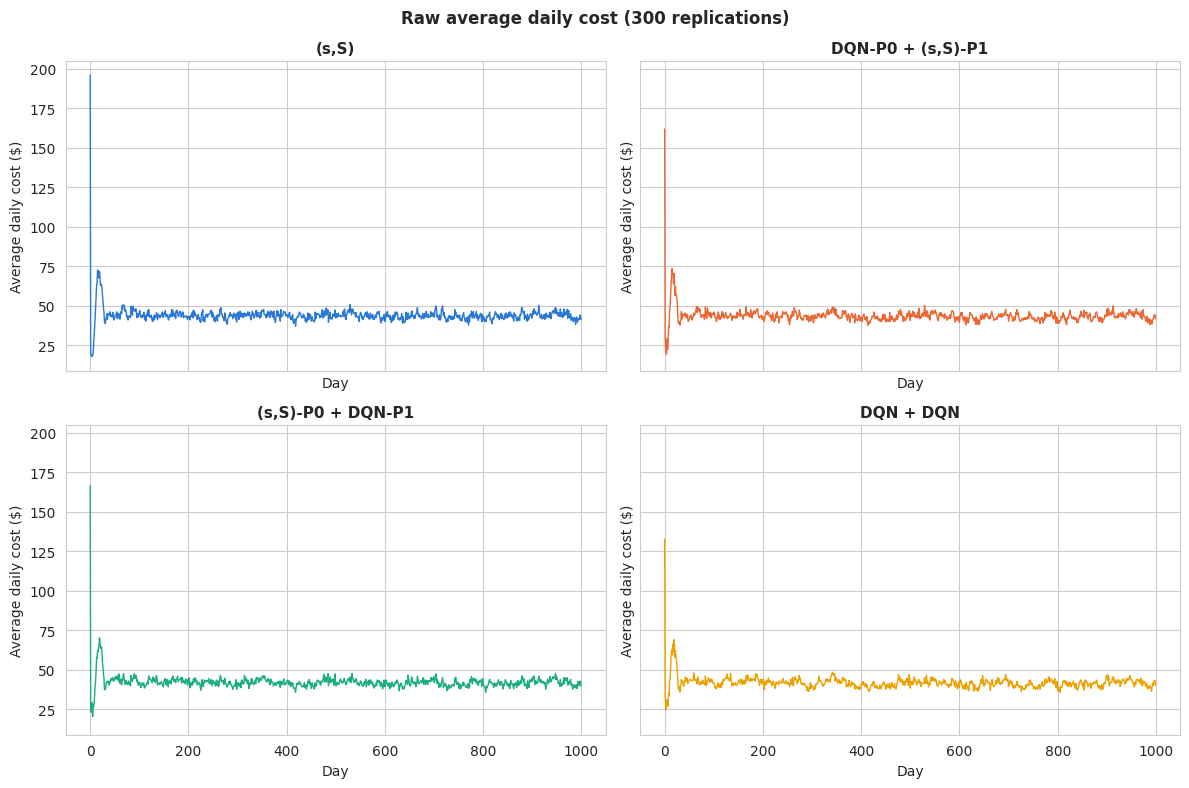

In [15]:
avg_daily = {
    name: np.mean([ep["total_daily_cost"] for ep in eps], axis=0)
    for name, eps in episodes.items()
}

fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True, sharey=True)
for ax, (name, y) in zip(axes.flat, avg_daily.items()):
    ax.plot(y, linewidth=1, color=COLORS[name])
    ax.set_title(name, fontsize=11, fontweight="bold")
    ax.set_xlabel("Day")
    ax.set_ylabel("Average daily cost ($)")
fig.suptitle(f"Raw average daily cost ({NUM_REPLICATIONS} replications)", fontweight="bold")
plt.tight_layout()
plt.show()

## 3. Welch's Smoothing and Warmup Detection

Same plateau rule as `welch_procedure.ipynb`: first day after which a 50-day window stays within 5% of the second-half mean.

Note: the search starts at day 50, so 50 is the smallest warmup the rule can return. The y-axis of the plots is clipped: the first days (empty pipeline) cost much more.

In [16]:
def detect_warmup_length(smoothed_data: list[float], tolerance: float = 0.05) -> int:
    """First day after which the smoothed curve stays within `tolerance` of the steady-state mean."""
    if len(smoothed_data) < 100:
        return len(smoothed_data) // 2

    steady_state_mean = np.mean(smoothed_data[len(smoothed_data) // 2 :])
    threshold = tolerance * steady_state_mean
    for i in range(50, len(smoothed_data) - 50):
        if all(abs(v - steady_state_mean) <= threshold for v in smoothed_data[i : i + 50]):
            return i
    return len(smoothed_data) // 2


smoothed = {
    name: EvaluationMetrics()._compute_moving_average(list(y), WINDOW_SIZE)
    for name, y in avg_daily.items()
}
warmups = {name: detect_warmup_length(s) for name, s in smoothed.items()}

# One common warmup for all configurations keeps the comparison paired
WARMUP = max(warmups.values())

print("🔍 Detected warmup lengths:")
for name, w in warmups.items():
    print(f"   {name:<20} {w} days")
print(f"\n➡️  Common warmup used for the comparison: {WARMUP} days")

🔍 Detected warmup lengths:
   (s,S)                50 days
   DQN-P0 + (s,S)-P1    50 days
   (s,S)-P0 + DQN-P1    50 days
   DQN + DQN            50 days

➡️  Common warmup used for the comparison: 50 days


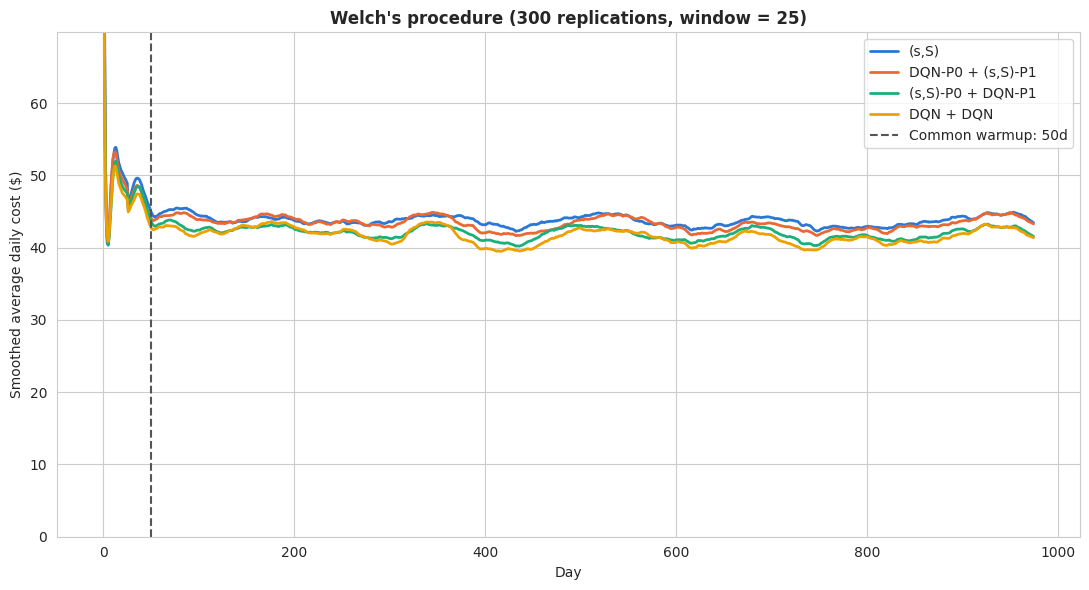

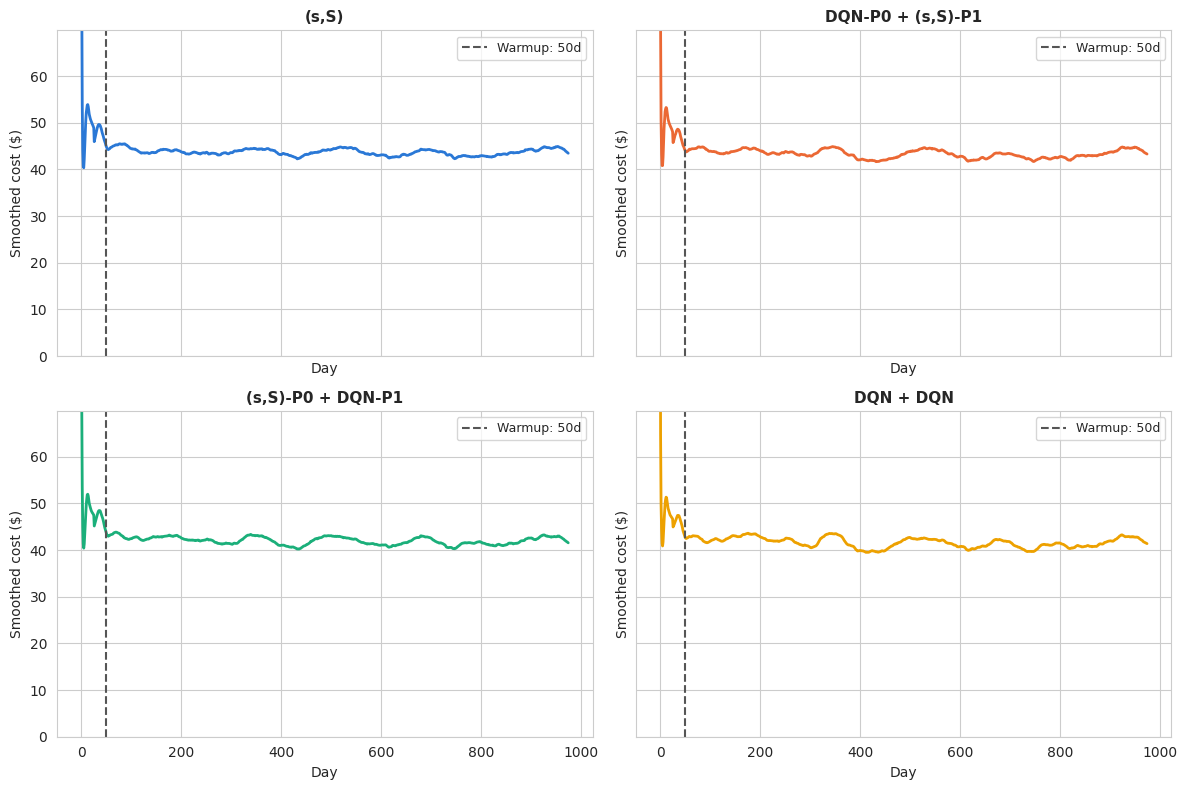

In [17]:
fig, ax = plt.subplots(figsize=(11, 6))
for name, s in smoothed.items():
    ax.plot(s, label=name, linewidth=2, color=COLORS[name])
ax.axvline(WARMUP, color="#555", linestyle="--", linewidth=1.5, label=f"Common warmup: {WARMUP}d")
ax.set_xlabel("Day")
ax.set_ylabel("Smoothed average daily cost ($)")
ax.set_title(
    f"Welch's procedure ({NUM_REPLICATIONS} replications, window = {WINDOW_SIZE})",
    fontweight="bold",
)
# Day-0 transient (initial stock ~ steady state, empty pipeline) is clipped from view
Y_TOP = 1.6 * max(np.mean(s[len(s) // 2 :]) for s in smoothed.values())
ax.set_ylim(0, Y_TOP)
ax.legend()
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True, sharey=True)
for ax, (name, s) in zip(axes.flat, smoothed.items()):
    ax.plot(s, linewidth=2, color=COLORS[name])
    ax.axvline(warmups[name], color="#555", linestyle="--", linewidth=1.5, label=f"Warmup: {warmups[name]}d")
    ax.set_title(name, fontsize=11, fontweight="bold")
    ax.set_xlabel("Day")
    ax.set_ylabel("Smoothed cost ($)")
    ax.set_ylim(0, Y_TOP)
    ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

## 4. Steady-State Comparison

CI95 = Student-t over replications. **Δ vs (s,S)** is the paired difference per seed (common random numbers), so its CI is much tighter than the unpaired ones.

In [8]:
table = summarize_comparison(episodes, warmup=WARMUP, reference="(s,S)")
display(Markdown(format_comparison(table)))

| Policy | $/day ± CI95 | Δ vs ref ± CI95 | P0 $/day (ord/hold/short) | P1 $/day (ord/hold/short) | Fill rate P0/P1 | No-stockout days P0/P1 |
|---|---|---|---|---|---|---|
| (s,S) | 43.70 ± 0.36 | +0.00 ± 0.00 | 20.10 (2.9/11.8/5.3) | 23.61 (4.2/13.5/5.9) | 83.3% / 83.2% | 87.4% / 87.9% |
| DQN-P0 + (s,S)-P1 | 43.32 ± 0.47 | -0.38 ± 0.22 | 19.71 (4.1/7.7/8.0) | 23.61 (4.2/13.5/5.9) | 73.9% / 83.2% | 80.7% / 87.9% |
| (s,S)-P0 + DQN-P1 | 42.00 ± 0.40 | -1.70 ± 0.20 | 20.10 (2.9/11.8/5.3) | 21.90 (6.2/9.2/6.5) | 83.3% / 78.2% | 87.4% / 84.8% |
| DQN + DQN | 41.62 ± 0.52 | -2.09 ± 0.32 | 19.71 (4.1/7.7/8.0) | 21.90 (6.2/9.2/6.5) | 73.9% / 78.2% | 80.7% / 84.8% |

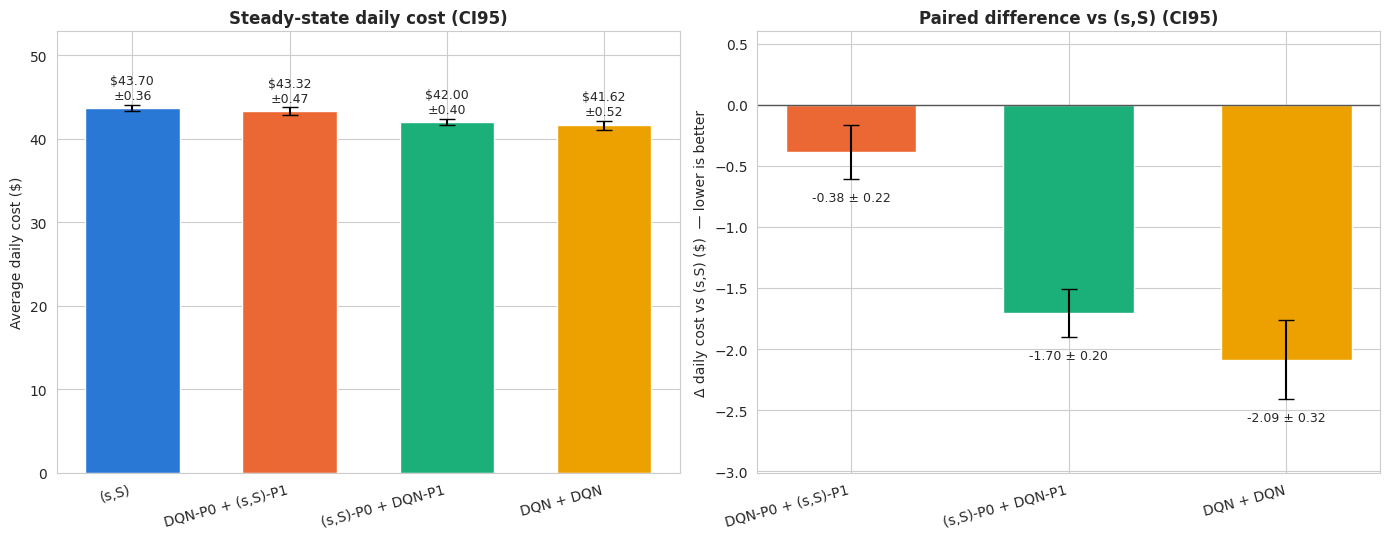

In [9]:
names = list(table.index)
x = np.arange(len(names))
colors = [COLORS[n] for n in names]

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

ax = axes[0]
ax.bar(x, table["cost_mean"], yerr=table["cost_ci"], capsize=6, color=colors, width=0.6)
for i, (m, c) in enumerate(zip(table["cost_mean"], table["cost_ci"])):
    ax.text(i, m + c + 0.3, f"${m:.2f}\n±{c:.2f}", ha="center", va="bottom", fontsize=9)
ax.set_xticks(x, names, rotation=15, ha="right")
ax.set_ylabel("Average daily cost ($)")
ax.set_title("Steady-state daily cost (CI95)", fontweight="bold")
ax.set_ylim(0, (table["cost_mean"] + table["cost_ci"]).max() * 1.2)

ax = axes[1]
diff = table.drop(index="(s,S)")
xd = np.arange(len(diff))
ax.bar(xd, diff["diff_vs_ref_mean"], yerr=diff["diff_vs_ref_ci"], capsize=6,
       color=[COLORS[n] for n in diff.index], width=0.6)
ax.axhline(0, color="#555", linewidth=1)
lo = (diff["diff_vs_ref_mean"] - diff["diff_vs_ref_ci"]).min()
hi = (diff["diff_vs_ref_mean"] + diff["diff_vs_ref_ci"]).max()
pad = 0.25 * (max(hi, 0) - min(lo, 0))
ax.set_ylim(min(lo, 0) - pad, max(hi, 0) + pad)
for i, (m, c) in enumerate(zip(diff["diff_vs_ref_mean"], diff["diff_vs_ref_ci"])):
    ax.text(i, m + (c + 0.1) * np.sign(m or 1), f"{m:+.2f} ± {c:.2f}",
            ha="center", va="bottom" if m >= 0 else "top", fontsize=9)
ax.set_xticks(xd, diff.index, rotation=15, ha="right")
ax.set_ylabel("Δ daily cost vs (s,S) ($)  — lower is better")
ax.set_title("Paired difference vs (s,S) (CI95)", fontweight="bold")

plt.tight_layout()
plt.show()

## 5. Cost Breakdown per Product

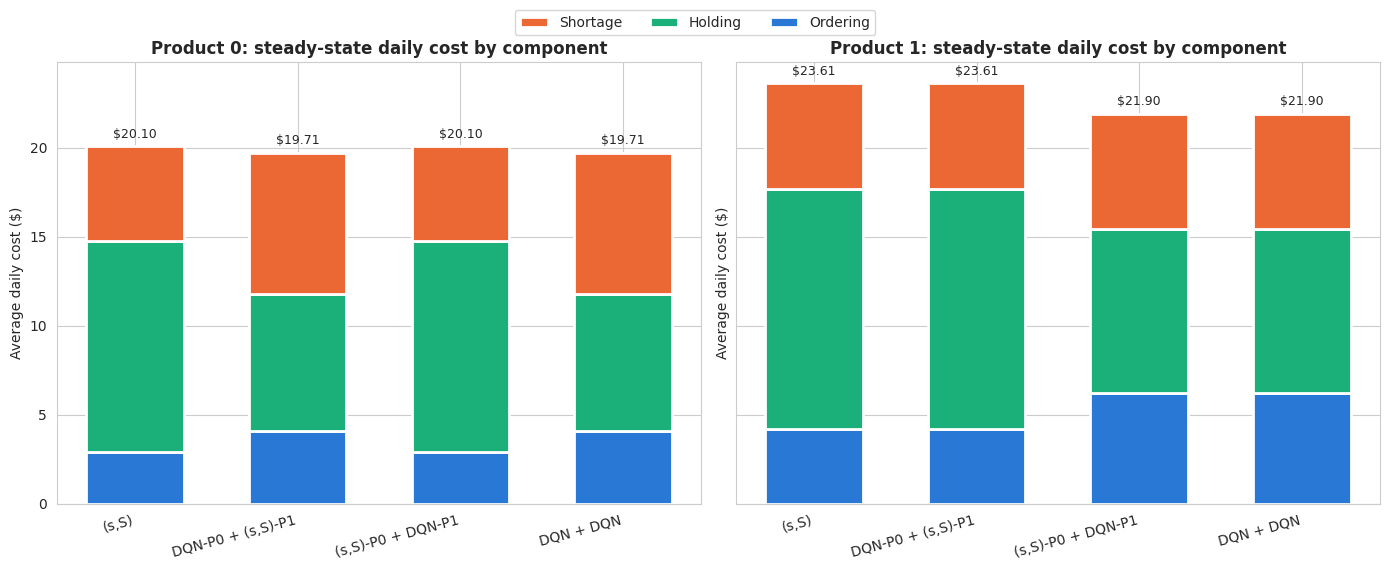

In [10]:
components = ["ordering", "holding", "shortage"]
comp_colors = {"ordering": "#2a78d6", "holding": "#1baf7a", "shortage": "#eb6834"}

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharey=True)
for j, ax in enumerate(axes):
    bottom = np.zeros(len(names))
    for comp in components:
        vals = table[f"p{j}_{comp}"].to_numpy()
        ax.bar(x, vals, bottom=bottom, color=comp_colors[comp], width=0.6,
               edgecolor="white", linewidth=2, label=comp.capitalize())
        bottom += vals
    for i, total in enumerate(bottom):
        ax.text(i, total + 0.3, f"${total:.2f}", ha="center", va="bottom", fontsize=9)
    ax.set_xticks(x, names, rotation=15, ha="right")
    ax.set_title(f"Product {j}: steady-state daily cost by component", fontweight="bold")
    ax.set_ylabel("Average daily cost ($)")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles[::-1], labels[::-1], loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.04))
plt.tight_layout()
plt.show()

## 6. Service Level per Product

- **Fill rate**: units served immediately from stock / units demanded
- **No-stockout days**: fraction of days ending without backorders

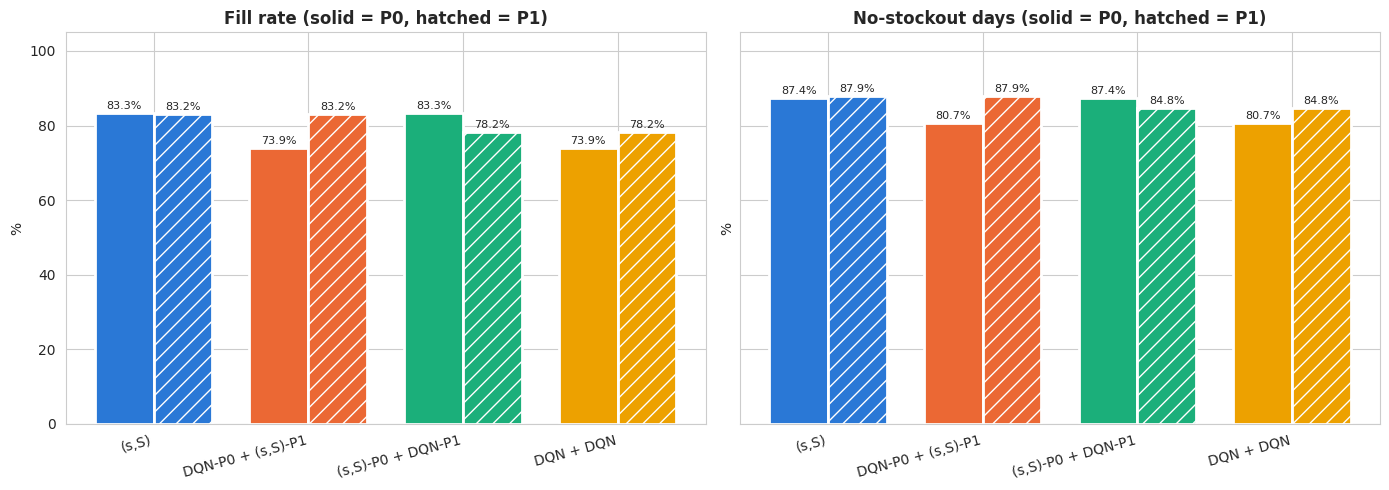

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
width = 0.38
for ax, (metric, title) in zip(axes, [("fill_rate", "Fill rate"), ("no_stockout", "No-stockout days")]):
    for j, offset in ((0, -width / 2), (1, width / 2)):
        vals = table[f"p{j}_{metric}"].to_numpy() * 100
        bars = ax.bar(x + offset, vals, width=width, color=colors, edgecolor="white", linewidth=2,
                      hatch=None if j == 0 else "//", label=f"Product {j}")
        for b, v in zip(bars, vals):
            ax.text(b.get_x() + b.get_width() / 2, v + 0.5, f"{v:.1f}%", ha="center", va="bottom", fontsize=8)
    ax.set_xticks(x, names, rotation=15, ha="right")
    ax.set_ylim(0, 105)
    ax.set_ylabel("%")
    ax.set_title(f"{title} (solid = P0, hatched = P1)", fontweight="bold")
plt.tight_layout()
plt.show()

## 7. Net Inventory Distribution (steady state)

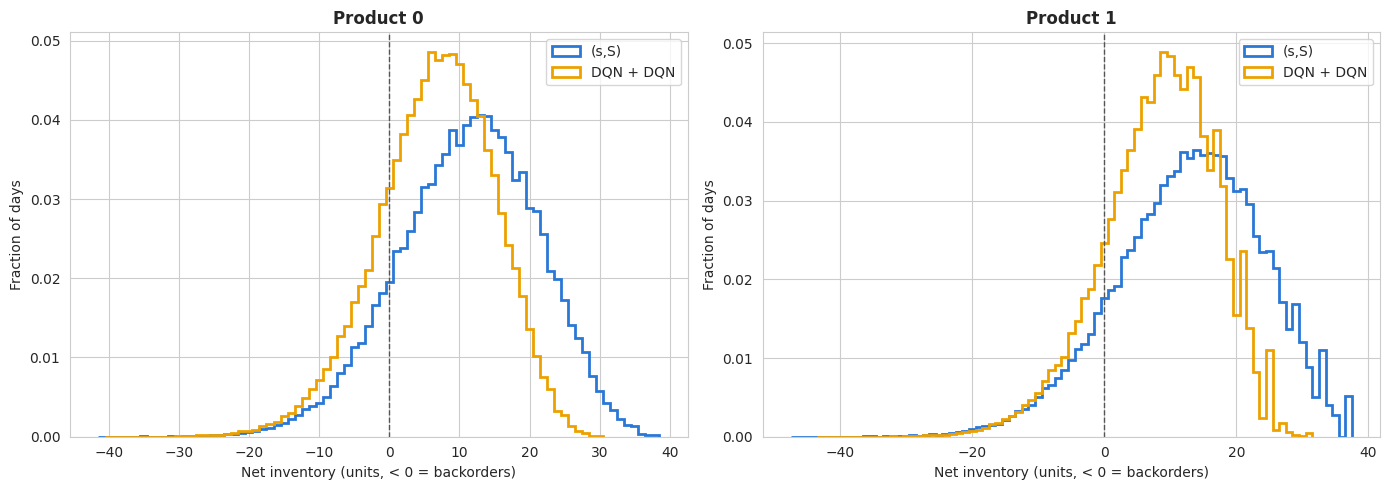

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for j, ax in enumerate(axes):
    for name in ["(s,S)", "DQN + DQN"]:
        inv = np.concatenate([ep[f"net_inv_{j}"][WARMUP:] for ep in episodes[name]])
        ax.hist(inv, bins=np.arange(inv.min(), inv.max() + 2) - 0.5, density=True,
                histtype="step", linewidth=2, color=COLORS[name], label=name)
    ax.axvline(0, color="#555", linestyle="--", linewidth=1)
    ax.set_xlabel("Net inventory (units, < 0 = backorders)")
    ax.set_ylabel("Fraction of days")
    ax.set_title(f"Product {j}", fontweight="bold")
    ax.legend()
plt.tight_layout()
plt.show()

## 8. Training Curves

Greedy policy evaluated every 50k steps on 5 validation seeds (disjoint from the test seeds), product cost only. Dashed line: (s,S) on the same validation seeds.

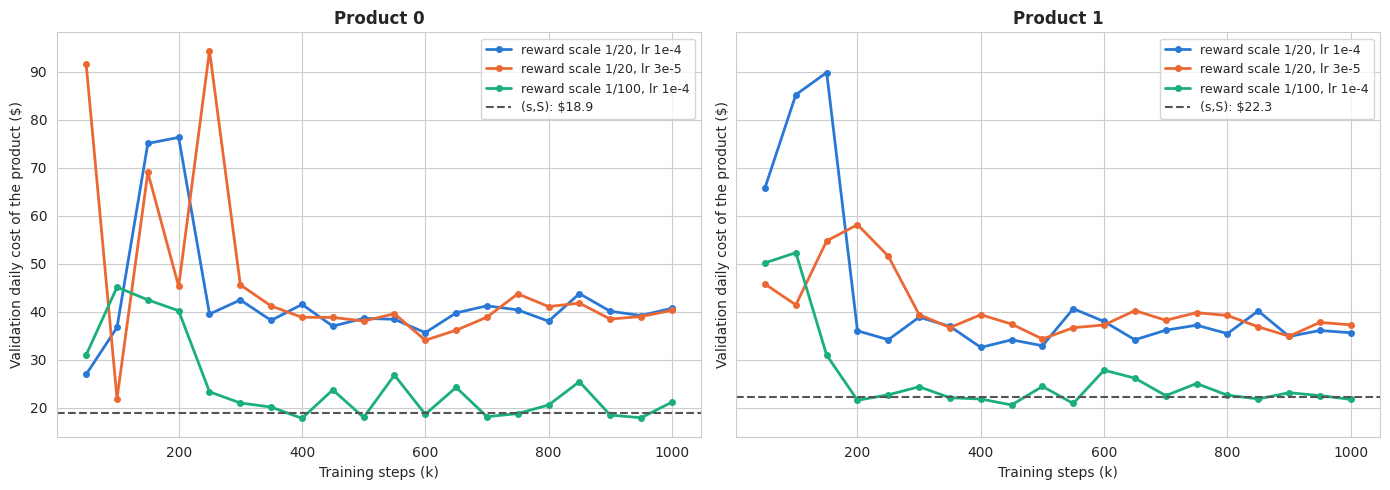

In [13]:
ss_validation = [run_joint_episode(ss, seed, SIM_DAYS) for seed in VALIDATION_SEEDS]
run_colors = ["#2a78d6", "#eb6834", "#1baf7a"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for j, ax in enumerate(axes):
    for color, (label, run) in zip(run_colors, TRAINING_RUNS.items()):
        path = ROOT / f"models/dqn_p{j}_{run}/eval_history.json"
        if not path.exists():
            continue
        hist = json.loads(path.read_text())
        ax.plot([r["timesteps"] / 1e3 for r in hist], [r["product_cost"] for r in hist],
                marker="o", markersize=4, linewidth=2, color=color, label=label)
    ref = np.mean([ep[f"cost_{j}"][200:].mean() for ep in ss_validation])
    ax.axhline(ref, color="#555", linestyle="--", linewidth=1.5, label=f"(s,S): ${ref:.1f}")
    ax.set_xlabel("Training steps (k)")
    ax.set_ylabel("Validation daily cost of the product ($)")
    ax.set_title(f"Product {j}", fontweight="bold")
    ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

## 9. Export Results

In [14]:
export_data = {
    "configuration": {
        "sim_days": SIM_DAYS,
        "num_replications": NUM_REPLICATIONS,
        "window_size": WINDOW_SIZE,
        "warmup_days": int(WARMUP),
        "detected_warmups": {k: int(v) for k, v in warmups.items()},
        "models": {f"P{k}": str(v.relative_to(ROOT)) for k, v in MODEL_DIRS.items()},
        "seeds": [int(s) for s in WELCH_SEEDS],
    },
    "results": json.loads(table.to_json(orient="index")),
}

results_dir = ROOT / "results"
results_dir.mkdir(exist_ok=True)
output_path = results_dir / "welch_procedure_product_dqn_results.json"
output_path.write_text(json.dumps(export_data, indent=2))
print(f"✅ Results saved to: {output_path}")

✅ Results saved to: ../results/welch_procedure_product_dqn_results.json
